# Signature forecast trading policy

Initial wealth: **$100**. The SPY allocation is `0.20 + 0.60 × percentile`, using a frozen distribution of pre-test walk-forward forecasts. Fractional shares, zero costs, zero cash interest, and a 0% risk-free rate are assumed.

The close-to-close result assumes an idealized same-close fill after observing that close. The next-open-to-close row trades after the signal is available and holds cash overnight. Maximum drawdown includes the initial $100 peak; Sharpe uses daily simple portfolio returns, sample standard deviation and 252 sessions/year.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown
PROJECT = Path.cwd()
if not (PROJECT / 'src' / 'backtest_signature_policy.py').exists():
    PROJECT = PROJECT / 'Signature_Price_Forecast'
OUTPUT = PROJECT / 'results' / 'trading_policy'
summary = pd.read_csv(OUTPUT / 'summary.csv')
display(summary[['strategy', 'execution', 'final_wealth', 'total_return_pct', 'max_drawdown_pct', 'annualized_sharpe_rf0']].round(4))

,strategy,execution,final_wealth,total_return_pct,max_drawdown_pct,annualized_sharpe_rf0
0,Signature percentile 20-80%,Idealized close-to-close,110.7582,10.7582,6.3473,1.1731
1,Fixed 50% SPY / 50% cash,Idealized close-to-close,109.5878,9.5878,5.1171,1.1437
2,Buy and hold SPY,Idealized close-to-close,119.4297,19.4297,10.0351,1.1437
3,Signature percentile 20-80%,Next open to close; cash overnight,97.0063,-2.9937,7.1187,-0.3906


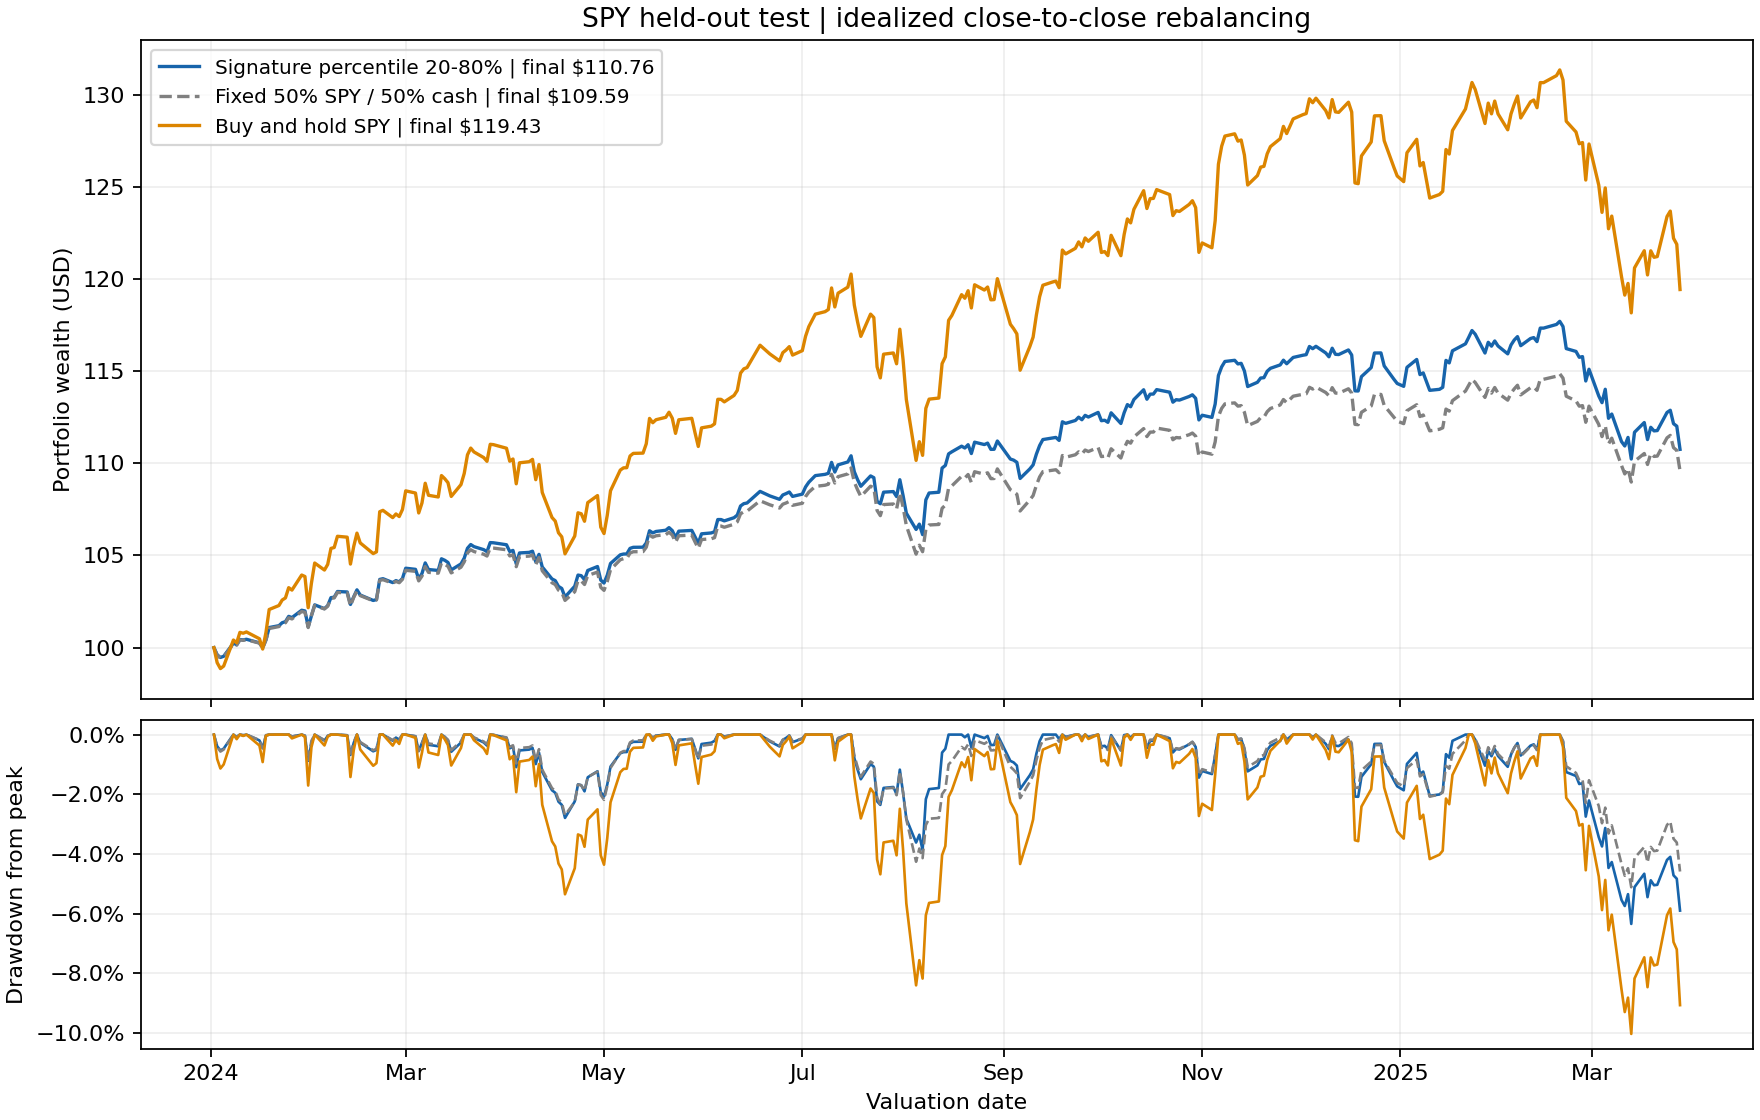

In [2]:
display(Image(filename=str(OUTPUT / 'equity_and_drawdown.png')))

In [3]:
daily = pd.read_csv(OUTPUT / 'daily_close_to_close.csv')
display(daily[['issue_date', 'target_date', 'predicted_return', 'training_percentile', 'allocation', 'wealth_before', 'invested_dollars', 'cash_dollars', 'wealth', 'drawdown']].head(10))
display(pd.DataFrame([json.loads((OUTPUT / 'calibration_info.json').read_text())]))

,issue_date,target_date,predicted_return,training_percentile,allocation,wealth_before,invested_dollars,cash_dollars,wealth,drawdown
0,2024-01-02,2024-01-03,0.000427,0.461640,0.476984,100.000000,47.698413,52.301587,99.610200,-0.003898
1,2024-01-03,2024-01-04,0.000373,0.407407,0.444444,99.610200,44.271200,55.339000,99.467802,-0.005322
2,2024-01-04,2024-01-05,0.000402,0.429894,0.457937,99.467802,45.549938,53.917864,99.530219,-0.004698
3,2024-01-05,2024-01-08,0.000458,0.501323,0.500794,99.530219,49.844102,49.686118,100.242011,0.000000
4,2024-01-08,2024-01-09,0.000489,0.538360,0.523016,100.242011,52.428163,47.813848,100.162149,-0.000797
5,2024-01-09,2024-01-10,0.000444,0.484127,0.490476,100.162149,49.127149,51.035000,100.440526,0.000000
6,2024-01-10,2024-01-11,0.000438,0.478836,0.487302,100.440526,48.944828,51.495698,100.418252,-0.000222
7,2024-01-11,2024-01-12,0.000483,0.527778,0.516667,100.418252,51.882763,48.535488,100.454248,0.000000
8,2024-01-12,2024-01-16,0.000498,0.547619,0.528571,100.454248,53.097245,47.357002,100.259828,-0.001935
9,2024-01-16,2024-01-17,0.000410,0.441799,0.465079,100.259828,46.628777,53.631051,100.000250,-0.004519


,identity,csv_sha256,method,forecast_count,issue_first,issue_last,latest_target,known_by_issue_close,config,selection
0,67ef54ef2cc54f88360e15cfa18c5316e1fd9d6624ff8d...,7743fae23ddd07ecb19510ec9faebd042cbe9ffd8e5565...,Frozen empirical mid-CDF of causal pre-test wa...,756,2020-12-29,2023-12-29,2024-01-02,2024-01-02,"{'window': 20, 'signature_depth': 2, 'regime_d...",Most recent max_train matured examples at the ...


In [4]:
display(Markdown((OUTPUT / 'report.md').read_text(encoding='utf8')))

# Signature forecast trading policy backtest

Initial wealth: **$100.00**. Test: **310 sessions**, 2024-01-03 to 2025-03-28.

| Policy | Holding period | Final wealth | Total return | Max drawdown | Annualized Sharpe |
|---|---|---:|---:|---:|---:|
| Signature percentile 20-80% | Idealized close-to-close | $110.76 | 10.7582% | 6.3473% | 1.1731 |
| Fixed 50% SPY / 50% cash | Idealized close-to-close | $109.59 | 9.5878% | 5.1171% | 1.1437 |
| Buy and hold SPY | Idealized close-to-close | $119.43 | 19.4297% | 10.0351% | 1.1437 |
| Signature percentile 20-80% | Next open to close; cash overnight | $97.01 | -2.9937% | 7.1187% | -0.3906 |

## Allocation

Each day invest `20% + 60% × frozen training forecast percentile` of current wealth in SPY; hold the remainder as cash. A percentile is the number of calibration forecasts strictly below the current forecast plus half the ties, divided by the number of calibration forecasts. Forecasts outside the calibration range receive 20% or 80%. The rule is fixed; no test-return optimization or test-wide ranking is used.

Calibration: **756 causal walk-forward forecasts**, issued 2020-12-29 through 2023-12-29; all outcomes were known by the first test issue close (2024-01-02). The calibration window matches the first test model's matured training-example window. The saved validation-selected forecasting configuration is reused. The first, middle and last saved test predictions were reproduced to confirm the same forecasting pipeline.

Realized allocations: 22.86% to 79.92%; mean 53.13%.

## Calculation and execution assumptions

- Convert realized log returns to simple returns with `exp(log_return) - 1`.
- Wealth evolves as `W_next = W_current × (1 + allocation × asset_simple_return)`.
- Fractional shares are allowed; no borrowing or short selling.
- Cash interest, risk-free rate, transaction costs and slippage are all zero.
- Maximum drawdown is the largest daily decline from a running wealth peak, including the initial $100.
- Annualized Sharpe is `sqrt(252) × mean(daily portfolio returns) / sample standard deviation`. The square-root annualization is the usual simplifying convention; see [Sharpe's discussion of differential returns and time dependence](https://web.stanford.edu/~wfsharpe/art/sr/SR.htm).
- The primary close-to-close backtest assumes an exact issue-close fill after observing that close. This is an idealized signal study and cannot establish an executable same-close result.
- The next-open-to-close comparison uses only an already-issued forecast, trades from target-day open to close and holds cash overnight. Its holding period differs from the forecast target.
- Results use the local SPY price series as provided, with no additional dividend cashflows, taxes or currency conversion. Drawdown is based on daily marks, not intraday prices.

## Saved outputs

`daily_close_to_close.csv` and `daily_next_open_to_close.csv` contain allocations, cash, investment amounts, daily P&L, wealth and drawdown. `calibration_predictions.csv` preserves the pre-test reference forecasts. `run_info.json` records settings, source hashes and reproduction checks.


To recompute from the saved forecast CSV, run `python src/backtest_signature_policy.py` from this project folder. Calibration forecasts are reused only if their source identity and saved content match. The original forecasting notebook and its predictions are not overwritten.